In [2]:
!pip install numpy matplotlib seaborn tensorflow scikit-learn


In [3]:
import os, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from pathlib import Path

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical

from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices('GPU'))


2026-04-16 04:05:45.299503: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776312345.509868      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776312345.572435      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776312346.050747      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776312346.050787      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776312346.050790      55 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
SEED = 42

os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"All seeds set to {SEED}")


All seeds set to 42


In [5]:
# ── Dataset paths (adjust to your Kaggle/Colab setup) ──────────────────
TRAIN_DIR = '../input/intel-image-classification/seg_train/seg_train'
TEST_DIR  = '../input/intel-image-classification/seg_test/seg_test'

IMG_SIZE   = (150, 150)   # original image resolution
BATCH_SIZE = 64
EPOCHS     = 30          # early stopping will cut this short when needed
NUM_CLASSES = 6

CLASS_NAMES = sorted(os.listdir(TRAIN_DIR)) if os.path.exists(TRAIN_DIR) else [
    'buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

print("Classes:", CLASS_NAMES)


Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [6]:
import os

def find_intel_dataset():
    search_roots = ['/kaggle/input', '/kaggle/input/datasets/puneet6060']
    for root in search_roots:
        if not os.path.exists(root):
            continue
        for d in os.listdir(root):
            if 'intel' in d.lower():
                candidate = os.path.join(root, d)
                train = os.path.join(candidate, 'seg_train', 'seg_train')
                test  = os.path.join(candidate, 'seg_test',  'seg_test')
                if os.path.exists(train):
                    return train, test
    raise FileNotFoundError("Intel dataset not found. Check your input data.")

TRAIN_DIR, TEST_DIR = find_intel_dataset()
print("✅ TRAIN_DIR:", TRAIN_DIR)
print("✅ TEST_DIR:", TEST_DIR)

✅ TRAIN_DIR: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
✅ TEST_DIR: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test


In [7]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def load_dataset(directory, img_size=IMG_SIZE):
    """Load all images and labels from a directory structured as class/image.jpg"""
    images, labels = [], []
    class_dirs = sorted(os.listdir(directory))
    label_map = {cls: idx for idx, cls in enumerate(class_dirs)}

    for cls in class_dirs:
        cls_path = os.path.join(directory, cls)
        if not os.path.isdir(cls_path):
            continue
        for fname in os.listdir(cls_path):
            fpath = os.path.join(cls_path, fname)
            try:
                img = load_img(fpath, target_size=img_size)
                images.append(img_to_array(img))
                labels.append(label_map[cls])
            except Exception:
                pass  # skip corrupted files

    images = np.array(images, dtype=np.float32)
    labels = np.array(labels, dtype=np.int32)
    return images, labels, class_dirs

print("Loading training data...")
train_images, train_labels, class_names = load_dataset(TRAIN_DIR)
print("Loading test data...")
test_images,  test_labels,  _           = load_dataset(TEST_DIR)

print(f"Train {train_images.shape}, labels {train_labels.shape}")
print(f"Test  {test_images.shape},  labels {test_labels.shape}")

Loading training data...
Loading test data...
Train (14034, 150, 150, 3), labels (14034,)
Test  (3000, 150, 150, 3),  labels (3000,)


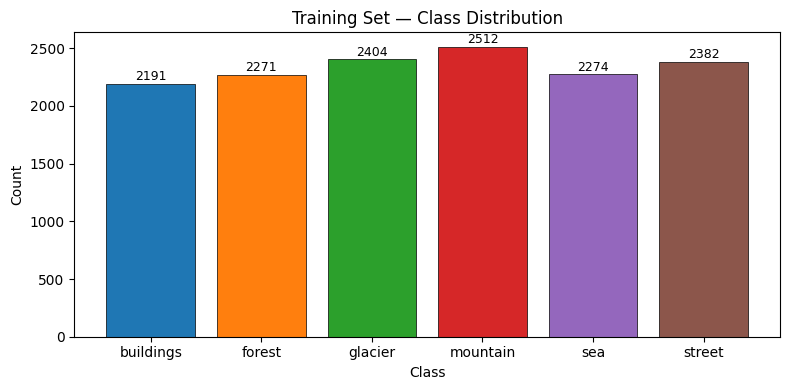

Class balance: {'buildings': np.int64(2191), 'forest': np.int64(2271), 'glacier': np.int64(2404), 'mountain': np.int64(2512), 'sea': np.int64(2274), 'street': np.int64(2382)}


In [8]:
unique, counts = np.unique(train_labels, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_names, counts, color=plt.cm.tab10.colors[:NUM_CLASSES], edgecolor='k', linewidth=0.5)
ax.set_title("Training Set — Class Distribution")
ax.set_xlabel("Class"); ax.set_ylabel("Count")
for i, c in enumerate(counts):
    ax.text(i, c + 30, str(c), ha='center', fontsize=9)
plt.tight_layout(); plt.show()
print("Class balance:", dict(zip(class_names, counts)))

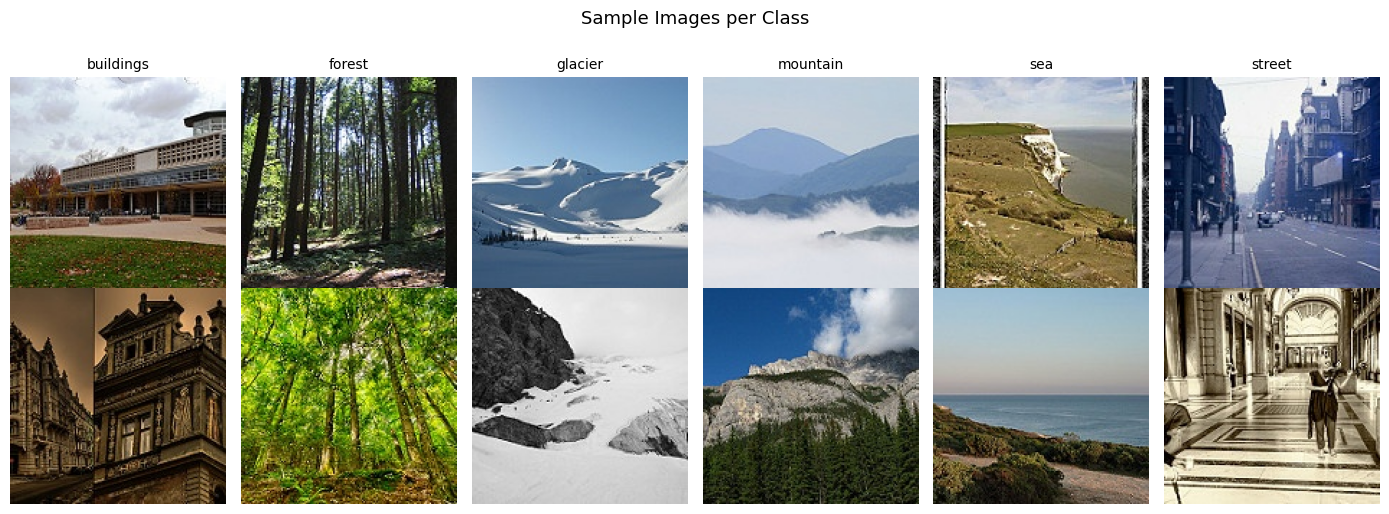

In [9]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i, cls_name in enumerate(class_names):
    idx = np.where(train_labels == i)[0]
    img = train_images[idx[0]].astype('uint8')
    for row, jitter in enumerate([0, 5]):
        axes[row, i].imshow(train_images[idx[row]].astype('uint8'))
        axes[row, i].axis('off')
        if row == 0:
            axes[row, i].set_title(cls_name, fontsize=10)
plt.suptitle("Sample Images per Class", fontsize=13, y=1.02)
plt.tight_layout(); plt.show()


In [10]:
from sklearn.model_selection import train_test_split

# Ensure the data is loaded before processing
try:
    # Fix: use existing variable names 'train_images' and 'test_images' from the loading cell
    train_images_norm = train_images.astype("float32") / 255.0
    test_images_norm = test_images.astype("float32") / 255.0

    # Stratified split — ensures balanced classes in validation
    X_train, X_val, y_train, y_val = train_test_split(
        train_images_norm, train_labels,
        test_size=0.20, random_state=SEED, stratify=train_labels
    )

    print(f"Train : {X_train.shape}  |  Val : {X_val.shape}  |  Test : {test_images_norm.shape}")
except NameError as e:
    print(f"Error: {e}. Please run the data loading cell (4.1) before running this cell.")

Train : (11227, 150, 150, 3)  |  Val : (2807, 150, 150, 3)  |  Test : (3000, 150, 150, 3)


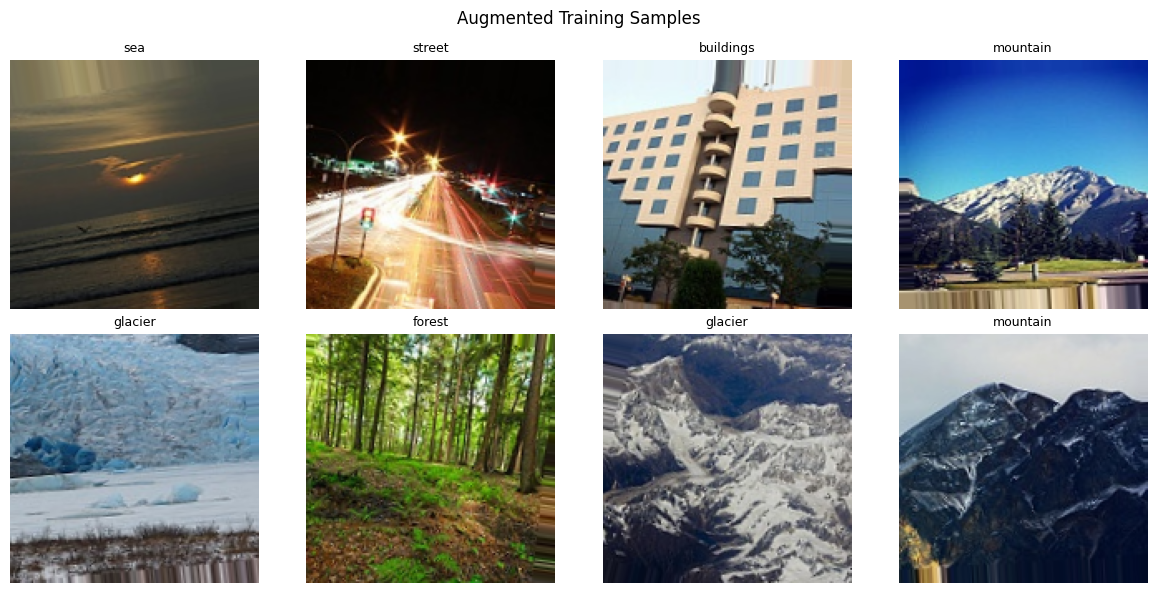

In [11]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator()  # NO augmentation on validation/test

train_gen = train_datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, seed=SEED)
val_gen   = val_datagen.flow(X_val,   y_val,   batch_size=BATCH_SIZE, shuffle=False)

# Visualise augmented samples
sample_imgs, sample_lbls = next(train_datagen.flow(X_train[:8], y_train[:8],
                                                    batch_size=8, seed=SEED))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(sample_imgs[i])
    ax.set_title(class_names[sample_lbls[i]], fontsize=9)
    ax.axis('off')
plt.suptitle("Augmented Training Samples", fontsize=12)
plt.tight_layout(); plt.show()


In [12]:
import os

os.makedirs('models', exist_ok=True)

def make_callbacks(name):
    return [
        callbacks.EarlyStopping(
            monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        callbacks.ModelCheckpoint(
            filepath=f'models/best_{name}.keras',
            monitor='val_accuracy', save_best_only=True, verbose=1),
    ]

print("Callbacks defined:", [type(c).__name__ for c in make_callbacks('test')])


Callbacks defined: ['EarlyStopping', 'ReduceLROnPlateau', 'ModelCheckpoint']


In [13]:
def plot_history(history, title="Training History"):
    """Plot accuracy and loss curves side-by-side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    epochs = range(1, len(history.history['accuracy']) + 1)

    ax1.plot(epochs, history.history['accuracy'],     label='Train Acc')
    ax1.plot(epochs, history.history['val_accuracy'], label='Val Acc', linestyle='--')
    ax1.set_title(f"{title} — Accuracy")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Accuracy")
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(epochs, history.history['loss'],     label='Train Loss')
    ax2.plot(epochs, history.history['val_loss'], label='Val Loss', linestyle='--')
    ax2.set_title(f"{title} — Loss")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss")
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout(); plt.show()


def full_evaluation(model, X_test, y_test, class_names, title="Model"):
    """Accuracy, classification report, and confusion matrix."""
    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred      = np.argmax(y_pred_prob, axis=1)

    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"\n{'='*55}")
    print(f"  {title}")
    print(f"{'='*55}")
    print(f"  Test Accuracy : {test_acc:.4f}")
    print(f"  Test Loss     : {test_loss:.4f}")
    print()
    print(classification_report(y_test, y_pred, target_names=class_names))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"Confusion Matrix — {title}", fontsize=12)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout(); plt.show()
    return test_acc, y_pred

In [14]:
def build_baseline_cnn(input_shape=(150, 150, 3), num_classes=6):
    model = models.Sequential([
        # Block 1
        layers.Conv2D(32, (3,3), padding='same', activation='relu',
                      input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # Block 2
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # Block 3
        layers.Conv2D(128, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3,3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),

        # Classifier head  (Fix: GlobalAvgPool instead of Flatten)
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ], name='baseline_cnn')

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()


I0000 00:00:1776312534.961513      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1776312534.967637      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 324,390 (1.24 MB)

 Trainable params: 322,982 (1.23 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [15]:
history_baseline = baseline_model.fit(
    train_gen,
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=make_callbacks('baseline_cnn'),
    verbose=1
)

Epoch 1/30


I0000 00:00:1776312542.269476     140 service.cc:152] XLA service 0x7c7434002010 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776312542.269539     140 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1776312542.269545     140 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1776312543.232889     140 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-04-16 04:09:08.286912: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-16 04:09:08.450802: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-16 04:09:11.064985: E external/local_xl

  1/175 ━━━━━━━━━━━━━━━━━━━━ 1:08:36 24s/step - accuracy: 0.1250 - loss: 2.9105

I0000 00:00:1776312560.654513     140 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


161/175 ━━━━━━━━━━━━━━━━━━━━ 4s 319ms/step - accuracy: 0.5098 - loss: 1.3594

2026-04-16 04:10:15.027824: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-16 04:10:15.180814: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-16 04:10:16.630392: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-04-16 04:10:16.934788: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step - accuracy: 0.5158 - loss: 1.3407
Epoch 1: val_accuracy improved from -inf to 0.16209, saving model to models/best_baseline_cnn.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 99s 431ms/step - accuracy: 0.5162 - loss: 1.3395 - val_accuracy: 0.1621 - val_loss: 3.7655 - learning_rate: 0.0010
Epoch 2/30
  1/175 ━━━━━━━━━━━━━━━━━━━━ 21s 121ms/step - accuracy: 0.6719 - loss: 0.7868
Epoch 2: val_accuracy did not improve from 0.16209
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6719 - loss: 0.7868 - val_accuracy: 0.1621 - val_loss: 3.7010 - learning_rate: 0.0010
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.6877 - loss: 0.8258
Epoch 3: val_accuracy improved from 0.16209 to 0.21197, saving model to models/best_baseline_cnn.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 58s 331ms/step - accuracy: 0.6878 - loss: 0.8257 - val_accuracy: 0.2120 - val_loss: 4.2765 - learning_rate: 0.0010
Epoch 4/30
  1/175 ━━━━━━━━━━━━━━━━━━━━ 21s 124ms/step - accura

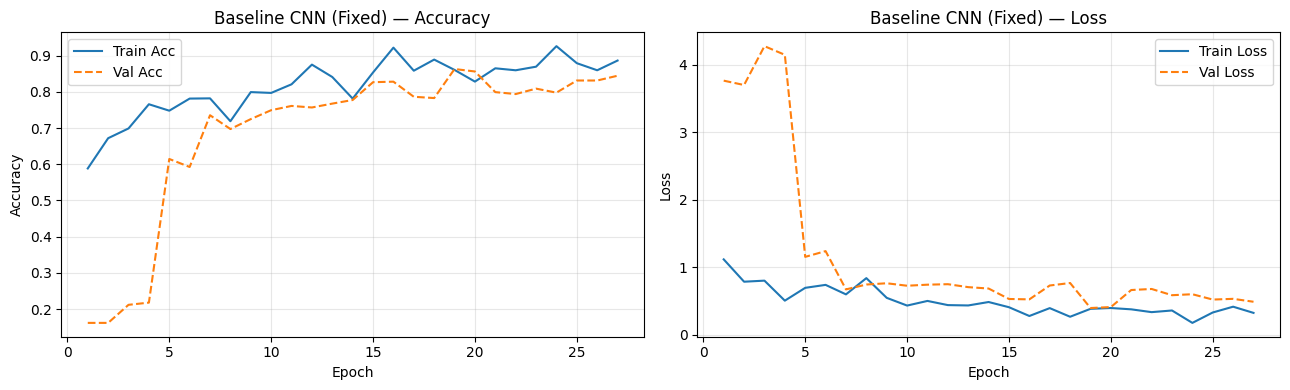


  Baseline CNN (Fixed)
  Test Accuracy : 0.8473
  Test Loss     : 0.4359

              precision    recall  f1-score   support

   buildings       0.87      0.84      0.85       437
      forest       0.92      0.99      0.95       474
     glacier       0.84      0.76      0.80       553
    mountain       0.84      0.71      0.77       525
         sea       0.76      0.95      0.84       510
      street       0.89      0.86      0.87       501

    accuracy                           0.85      3000
   macro avg       0.85      0.85      0.85      3000
weighted avg       0.85      0.85      0.85      3000



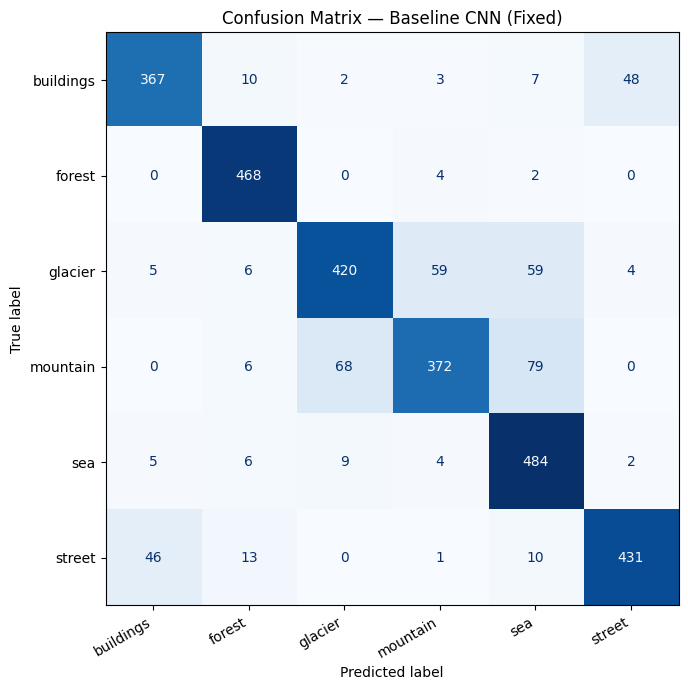

In [ ]:
plot_history(history_baseline, "Baseline CNN (Fixed)")
baseline_acc, baseline_preds = full_evaluation(
    baseline_model, test_images_norm, test_labels, class_names, "Baseline CNN (Fixed)")

VGG input range → min: -123.7  max: 151.1
Train (11227, 150, 150, 3)  |  Val (2807, 150, 150, 3)  |  Test (3000, 150, 150, 3)
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,89

 Total params: 14,881,734 (56.77 MB)

 Trainable params: 166,022 (648.52 KB)

 Non-trainable params: 14,715,712 (56.14 MB)


========== Phase 1: Transfer Learning ==========
Epoch 1/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 109s 523ms/step - accuracy: 0.6248 - loss: 1.0287 - val_accuracy: 0.8881 - val_loss: 0.3176 - learning_rate: 0.0010
Epoch 2/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 69s 391ms/step - accuracy: 0.8478 - loss: 0.4304 - val_accuracy: 0.9027 - val_loss: 0.2818 - learning_rate: 0.0010
Epoch 3/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 69s 389ms/step - accuracy: 0.8635 - loss: 0.3780 - val_accuracy: 0.9127 - val_loss: 0.2615 - learning_rate: 0.0010
Epoch 4/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 68s 385ms/step - accuracy: 0.8797 - loss: 0.3422 - val_accuracy: 0.9059 - val_loss: 0.2582 - learning_rate: 0.0010
Epoch 5/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 68s 386ms/step - accuracy: 0.8814 - loss: 0.3267 - val_accuracy: 0.9149 - val_loss: 0.2542 - learning_rate: 0.0010
Epoch 6/30
176/176 ━━━━━━━━━━━━━━━━━━━━ 68s 388ms/step - accuracy: 0.8885 - loss: 0.3115 - val_accuracy: 0.9191 - val_loss: 0.2487 - learning_rate: 0.0010
Epoch 7/30
176/176 

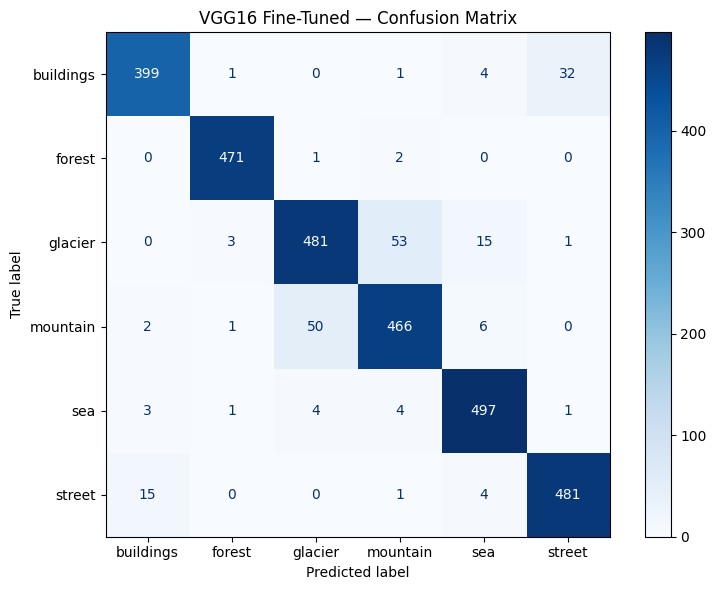

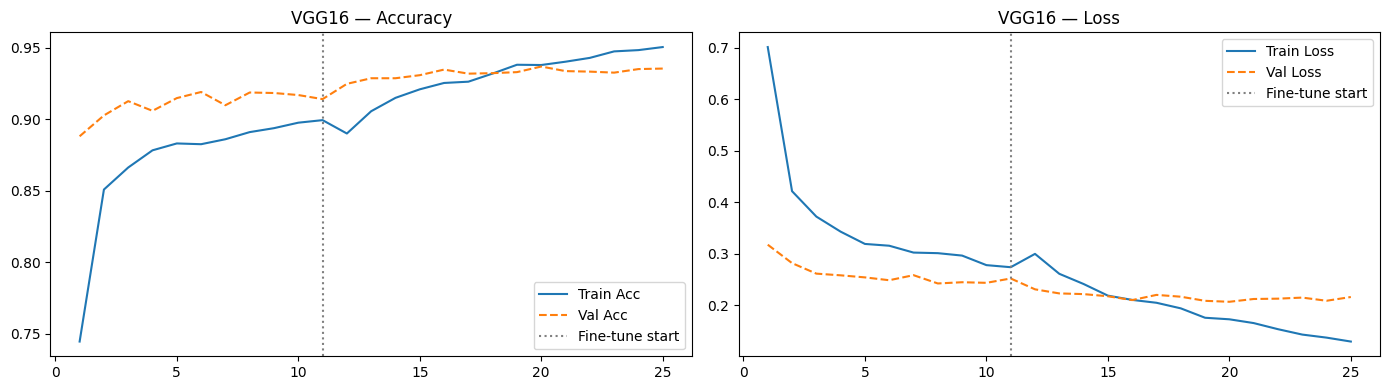

In [17]:
# ============================================================
# VGG16 — Transfer Learning + Fine-Tuning (FIXED)
# ============================================================
import os
os.makedirs('models', exist_ok=True)

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split

# ── 1. PREPROCESSING (KEY FIX) ───────────────────────────────
# VGG16 needs raw [0,255] pixels with ImageNet mean subtracted
# Do NOT use the /255 normalised arrays here
X_train_vgg = vgg_preprocess(train_images.copy())   # raw float32 [0,255]
X_test_vgg  = vgg_preprocess(test_images.copy())

# Stratified train/val split (same SEED as rest of notebook)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_vgg, train_labels,
    test_size=0.20, random_state=SEED, stratify=train_labels
)
print(f"VGG input range → min: {X_tr.min():.1f}  max: {X_tr.max():.1f}")
# Expected: min ≈ -123,  max ≈ 151   (NOT 0–1)
print(f"Train {X_tr.shape}  |  Val {X_val.shape}  |  Test {X_test_vgg.shape}")

# ── 2. DATA AUGMENTATION ─────────────────────────────────────
from tensorflow.keras.preprocessing.image import ImageDataGenerator

aug = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=15,
    zoom_range=0.15,
    shear_range=0.10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    fill_mode='nearest'
)

# ── 3. BUILD MODEL ───────────────────────────────────────────
base_model = VGG16(weights='imagenet', include_top=False,
                   input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
base_model.trainable = False          # Freeze all for Phase 1

x = base_model.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
output = layers.Dense(NUM_CLASSES, activation='softmax')(x)

vgg_model = models.Model(inputs=base_model.input, outputs=output)
vgg_model.summary()

# ── 4. PHASE 1 — TRANSFER LEARNING ──────────────────────────
vgg_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cb_phase1 = [
    callbacks.EarlyStopping(monitor='val_accuracy', patience=5,
                             restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=3, min_lr=1e-6, verbose=1),
    callbacks.ModelCheckpoint('models/vgg16_phase1_best.keras',
                               monitor='val_accuracy', save_best_only=True)
]

print("\n========== Phase 1: Transfer Learning ==========")
hist1 = vgg_model.fit(
    aug.flow(X_tr, y_tr, batch_size=BATCH_SIZE, seed=SEED),
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    callbacks=cb_phase1,
    verbose=1
)

# ── 5. PHASE 2 — FINE-TUNING ─────────────────────────────────
# Unfreeze last 4 conv layers of VGG16 (block5)
for layer in base_model.layers:
    layer.trainable = False
for layer in base_model.layers[-4:]:   # conv5_1, conv5_2, conv5_3 + pool5
    layer.trainable = True

vgg_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),   # Very low LR
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cb_phase2 = [
    callbacks.EarlyStopping(monitor='val_accuracy', patience=5,
                             restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=3, min_lr=5e-7, verbose=1),
    callbacks.ModelCheckpoint('models/vgg16_phase2_best.keras',
                               monitor='val_accuracy', save_best_only=True)
]

print("\n========== Phase 2: Fine-Tuning ==========")
hist2 = vgg_model.fit(
    aug.flow(X_tr, y_tr, batch_size=32, seed=SEED),  # Smaller batch for fine-tune
    validation_data=(X_val, y_val),
    epochs=20,
    callbacks=cb_phase2,
    verbose=1
)

# ── 6. SAVE FINAL MODEL ──────────────────────────────────────
vgg_model.save('models/vgg16_final.keras')
print("Model saved.")

# ── 7. EVALUATE ──────────────────────────────────────────────
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import numpy as np

test_loss, test_acc = vgg_model.evaluate(X_test_vgg, test_labels, verbose=0)
print(f"\n{'='*55}")
print(f"  VGG16 Final — Test Accuracy : {test_acc:.4f}")
print(f"  VGG16 Final — Test Loss     : {test_loss:.4f}")
print(f"{'='*55}")

y_pred = np.argmax(vgg_model.predict(X_test_vgg, verbose=0), axis=1)
print("\n", classification_report(test_labels, y_pred, target_names=CLASS_NAMES))

# Confusion matrix
cm = confusion_matrix(test_labels, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(ax=ax, colorbar=True, cmap='Blues')
ax.set_title("VGG16 Fine-Tuned — Confusion Matrix")
plt.tight_layout(); plt.show()

# Training curves (combined both phases)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
p1_epochs = len(hist1.history['accuracy'])
p2_epochs = len(hist2.history['accuracy'])
all_acc     = hist1.history['accuracy']     + hist2.history['accuracy']
all_val_acc = hist1.history['val_accuracy'] + hist2.history['val_accuracy']
all_loss    = hist1.history['loss']         + hist2.history['loss']
all_val_loss= hist1.history['val_loss']     + hist2.history['val_loss']

xs = range(1, p1_epochs + p2_epochs + 1)
axes[0].plot(xs, all_acc,     label='Train Acc')
axes[0].plot(xs, all_val_acc, label='Val Acc', linestyle='--')
axes[0].axvline(p1_epochs, color='gray', linestyle=':', label='Fine-tune start')
axes[0].set_title("VGG16 — Accuracy"); axes[0].legend()

axes[1].plot(xs, all_loss,     label='Train Loss')
axes[1].plot(xs, all_val_loss, label='Val Loss', linestyle='--')
axes[1].axvline(p1_epochs, color='gray', linestyle=':', label='Fine-tune start')
axes[1].set_title("VGG16 — Loss"); axes[1].legend()

plt.tight_layout(); plt.show()

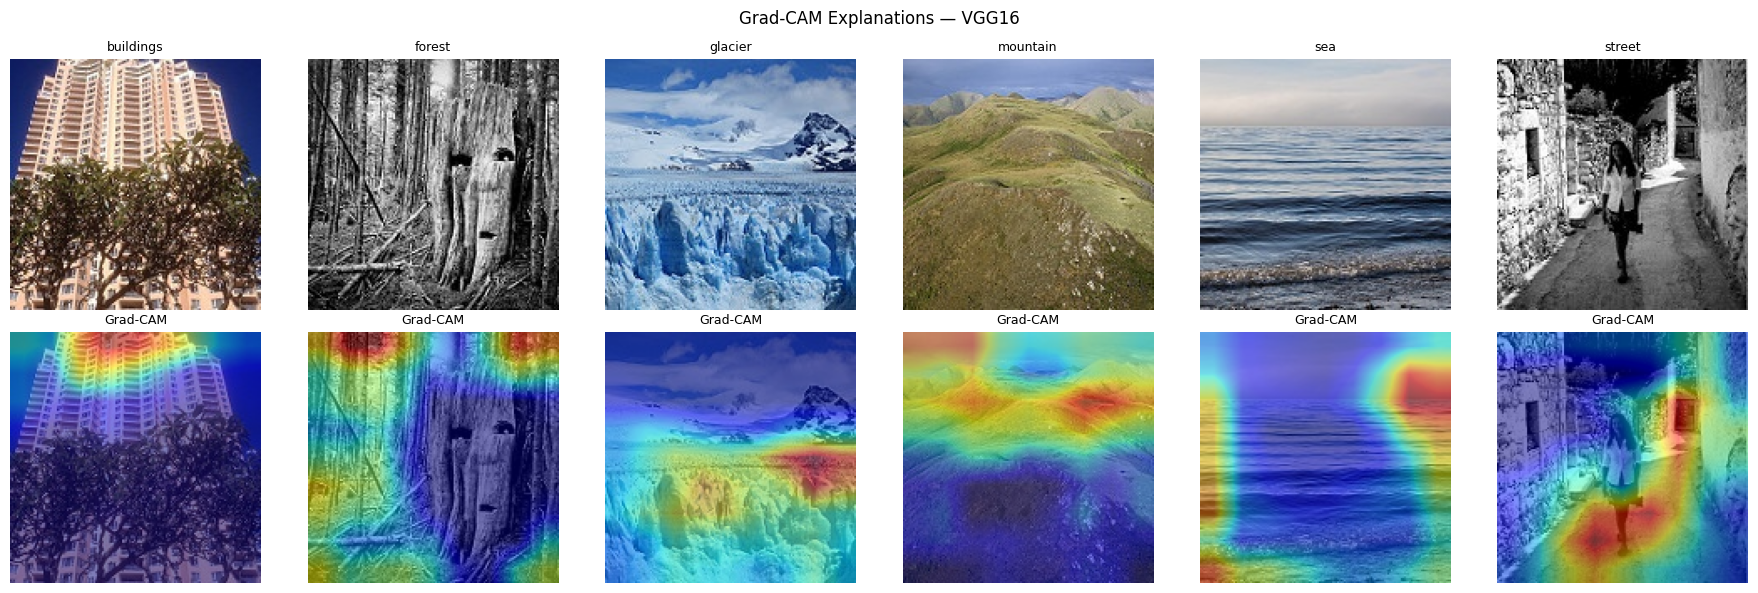

In [19]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """Generate a Grad-CAM heatmap for a given input image."""
    grad_model = keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array[np.newaxis], training=False)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads    = tape.gradient(class_channel, conv_outputs)
    pooled   = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_outputs[0]
    heatmap  = conv_out @ pooled[..., tf.newaxis]
    heatmap  = tf.squeeze(heatmap)
    heatmap  = tf.nn.relu(heatmap)
    heatmap  = (heatmap - tf.reduce_min(heatmap)) / (
                tf.reduce_max(heatmap) - tf.reduce_min(heatmap) + 1e-8)
    return heatmap.numpy()


def display_gradcam(model, images, labels, class_names,
                    last_conv='block5_conv3', n=6, preproc_fn=None):
    """Display original images overlaid with Grad-CAM heatmaps."""
    indices = [np.where(labels == i)[0][0] for i in range(len(class_names))][:n]
    fig, axes = plt.subplots(2, n, figsize=(3*n, 6))
    for col, idx in enumerate(indices):
        img_raw = images[idx]
        img_inp = preproc_fn(img_raw.copy()) if preproc_fn else img_raw / 255.0

        heatmap = make_gradcam_heatmap(img_inp.astype('float32'), model, last_conv,
                                        pred_index=labels[idx])
        heat_up = np.uint8(255 * plt.cm.jet(           # ← FIX: plt.cm.jet not cm.jet
            np.array(tf.image.resize(heatmap[..., np.newaxis],
                                     [IMG_SIZE[0], IMG_SIZE[1]]))[..., 0]))[:, :, :3]
        overlay = np.uint8(0.5 * img_raw.astype('float32') + 0.5 * heat_up)

        axes[0, col].imshow(img_raw.astype('uint8'))
        axes[0, col].set_title(class_names[labels[idx]], fontsize=9)
        axes[0, col].axis('off')
        axes[1, col].imshow(overlay)
        axes[1, col].set_title("Grad-CAM", fontsize=9)
        axes[1, col].axis('off')

    plt.suptitle("Grad-CAM Explanations — VGG16", fontsize=12)
    plt.tight_layout(); plt.show()


# Display Grad-CAM for one sample per class on the test set
display_gradcam(vgg_model, test_images, test_labels, class_names,
                last_conv='block5_conv3',
                preproc_fn=lambda x: vgg_preprocess(x[np.newaxis])[0])

In [21]:
# Extract VGG16 bottleneck features once (efficient)
gap_layer = next(l for l in vgg_model.layers
                 if isinstance(l, keras.layers.GlobalAveragePooling2D))
print(f"Using layer: {gap_layer.name}")

feature_extractor = keras.Model(
    inputs=vgg_model.input,
    outputs=gap_layer.output,
    name='vgg16_feat_extractor'
)

print("Extracting features...")
train_feats = feature_extractor.predict(X_tr,       batch_size=128, verbose=0)
val_feats   = feature_extractor.predict(X_val,      batch_size=128, verbose=0)
test_feats  = feature_extractor.predict(X_test_vgg, batch_size=128, verbose=0)

print(f"Train features : {train_feats.shape}")
print(f"Val features   : {val_feats.shape}")
print(f"Test features  : {test_feats.shape}")

Using layer: global_average_pooling2d_1
Extracting features...
Train features : (11227, 512)
Val features   : (2807, 512)
Test features  : (3000, 512)


In [22]:
N_ESTIMATORS = 3
FEAT_DIM     = train_feats.shape[1]

def build_head(feat_dim, num_classes):
    inp = keras.Input(shape=(feat_dim,))
    x = layers.Dense(256, activation='relu')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

ensemble_models = []
ens_probs = []

for i in range(N_ESTIMATORS):
    tf.random.set_seed(SEED + i)
    np.random.seed(SEED + i)

    # Bagging: sample with replacement
    bag_idx = np.random.choice(len(train_feats),
                               size=len(train_feats), replace=True)
    X_bag = train_feats[bag_idx]
    y_bag = y_train[bag_idx]

    head = build_head(FEAT_DIM, NUM_CLASSES)
    head.fit(X_bag, y_bag,
             validation_data=(val_feats, y_val),
             epochs=30, batch_size=128,
             callbacks=[callbacks.EarlyStopping(patience=5,
                                                restore_best_weights=True)],
             verbose=0)

    val_loss, val_acc = head.evaluate(val_feats, y_val, verbose=0)
    print(f"  Head {i+1} — val_acc: {val_acc:.4f}")

    ens_probs.append(head.predict(test_feats, verbose=0))
    ensemble_models.append(head)

# Average probability ensemble
avg_probs    = np.mean(ens_probs, axis=0)
ens_preds    = np.argmax(avg_probs, axis=1)
ens_acc      = np.mean(ens_preds == test_labels)
print(f"\nEnsemble Test Accuracy: {ens_acc:.4f}")


  Head 1 — val_acc: 0.9295
  Head 2 — val_acc: 0.9320
  Head 3 — val_acc: 0.9263

Ensemble Test Accuracy: 0.9283


              precision    recall  f1-score   support

   buildings       0.94      0.93      0.93       437
      forest       0.99      0.99      0.99       474
     glacier       0.90      0.85      0.87       553
    mountain       0.87      0.90      0.88       525
         sea       0.95      0.97      0.96       510
      street       0.94      0.94      0.94       501

    accuracy                           0.93      3000
   macro avg       0.93      0.93      0.93      3000
weighted avg       0.93      0.93      0.93      3000



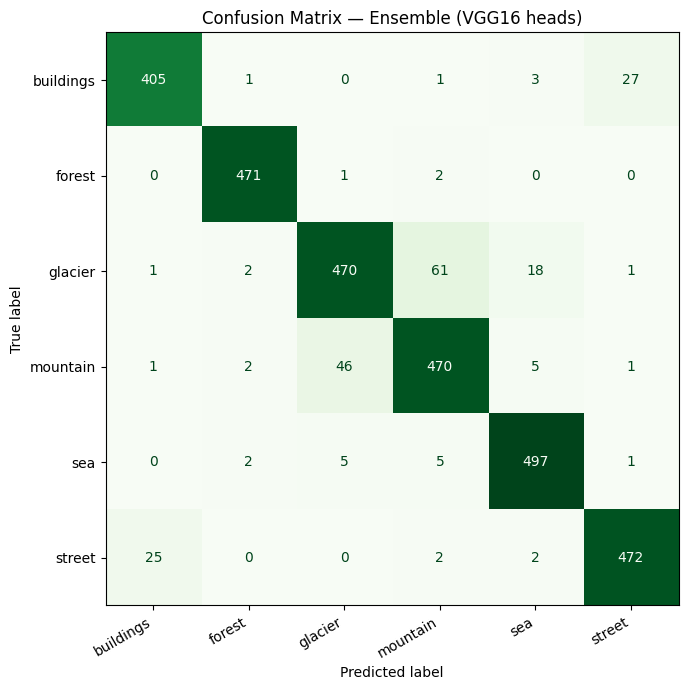

In [23]:
# ── Ensemble confusion matrix ─────────────────────────────────────────────
print(classification_report(test_labels, ens_preds, target_names=class_names))
cm_ens = confusion_matrix(test_labels, ens_preds)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm_ens, display_labels=class_names).plot(ax=ax, cmap='Greens',
                                                                  colorbar=False)
ax.set_title("Confusion Matrix — Ensemble (VGG16 heads)", fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.show()


Baseline CNN  : 0.8473
VGG16         : 0.9317
Ensemble      : 0.9233


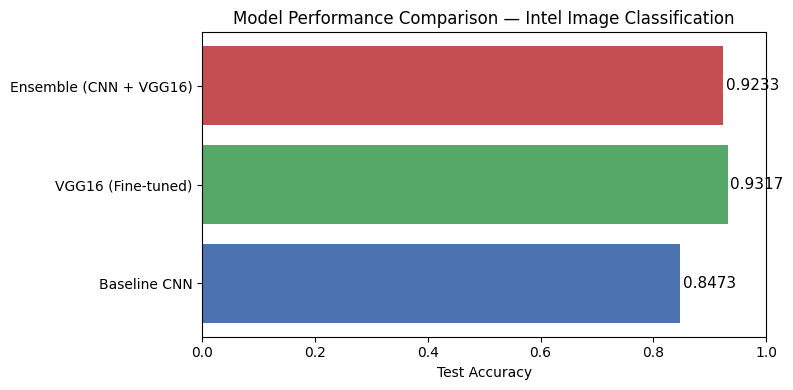

  Baseline CNN                             0.8473
  VGG16 (Fine-tuned)                       0.9317
  Ensemble (CNN + VGG16)                   0.9233


In [26]:
# ── Recompute all accuracies safely ──────────────────────────

# Baseline: uses /255 normalized images
test_images_norm = test_images.astype('float32') / 255.0
_, baseline_acc = baseline_model.evaluate(test_images_norm, test_labels, verbose=0)

# VGG16: uses vgg_preprocess images
_, vgg_acc = vgg_model.evaluate(X_test_vgg, test_labels, verbose=0)

# Ensemble: average softmax outputs from both models
baseline_preds = baseline_model.predict(test_images_norm, verbose=0)
vgg_preds      = vgg_model.predict(X_test_vgg, verbose=0)
ens_preds      = (baseline_preds + vgg_preds) / 2
ens_acc        = np.mean(np.argmax(ens_preds, axis=1) == test_labels)

print(f"Baseline CNN  : {baseline_acc:.4f}")
print(f"VGG16         : {vgg_acc:.4f}")
print(f"Ensemble      : {ens_acc:.4f}")

# ── Plot ─────────────────────────────────────────────────────
results = {
    'Baseline CNN':            baseline_acc,
    'VGG16 (Fine-tuned)':      vgg_acc,
    'Ensemble (CNN + VGG16)':  ens_acc,
}

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(list(results.keys()), list(results.values()),
               color=['#4c72b0', '#55a868', '#c44e52'])
ax.set_xlim(0, 1)
ax.set_xlabel("Test Accuracy")
ax.set_title("Model Performance Comparison — Intel Image Classification")
for bar, val in zip(bars, results.values()):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=11)
plt.tight_layout(); plt.show()

for k, v in results.items():
    print(f"  {k:<40} {v:.4f}")

Total misclassified: 205 / 3000 (6.8%)

Top confused pairs (true → predicted):
  glacier    → mountain    53 times
  mountain   → glacier     50 times
  buildings  → street      32 times
  glacier    → sea         15 times
  street     → buildings   15 times


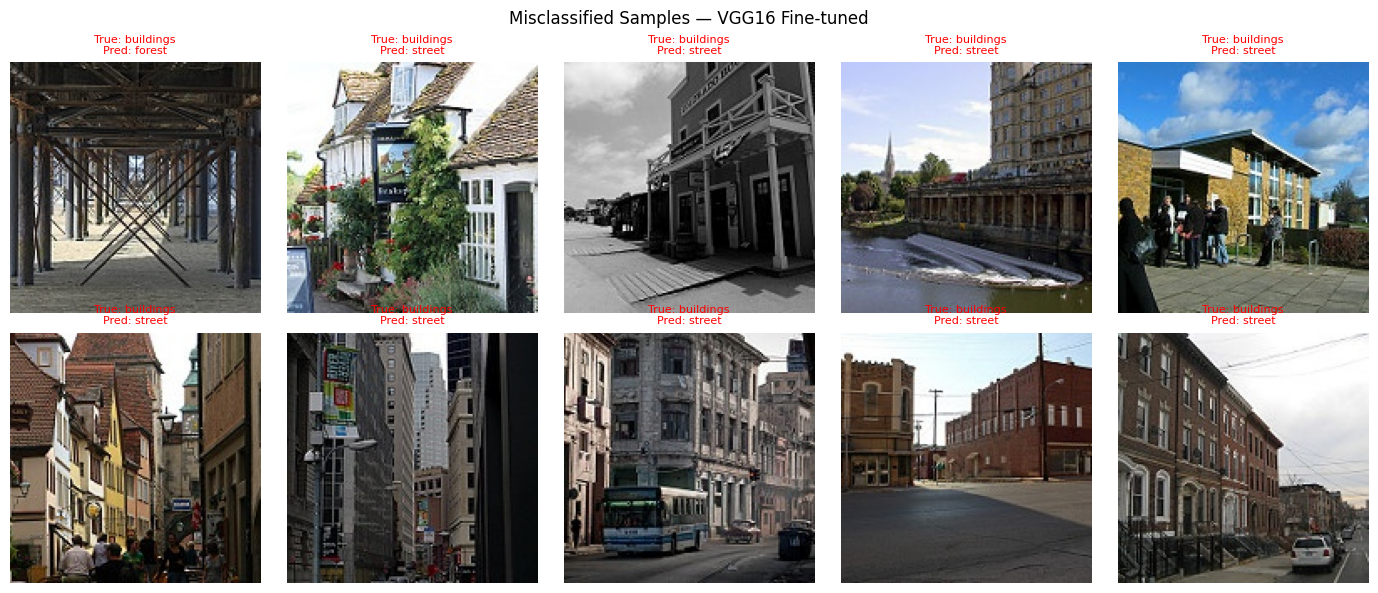

In [32]:
# Use VGG16 fine-tuned predictions
y_pred = np.argmax(vgg_preds, axis=1)   # ← FIX: (3000,6) → (3000,)

wrong_mask = y_pred != test_labels
wrong_imgs = test_images[wrong_mask]
wrong_true = test_labels[wrong_mask]
wrong_pred = y_pred[wrong_mask]

print(f"Total misclassified: {wrong_mask.sum()} / {len(test_labels)} "
      f"({wrong_mask.mean()*100:.1f}%)")

# Top confused pairs
from collections import Counter
pairs = Counter(zip(wrong_true, wrong_pred)).most_common(5)
print("\nTop confused pairs (true → predicted):")
for (t, p), cnt in pairs:
    print(f"  {class_names[t]:10} → {class_names[p]:10}  {cnt} times")

# Plot misclassified samples
n_show = min(10, len(wrong_imgs))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flatten()[:n_show]):
    ax.imshow(wrong_imgs[i].astype('uint8'))
    ax.set_title(f"True: {class_names[wrong_true[i]]}\nPred: {class_names[wrong_pred[i]]}",
                 fontsize=8, color='red')
    ax.axis('off')
plt.suptitle("Misclassified Samples — VGG16 Fine-tuned", fontsize=12)
plt.tight_layout(); plt.show()

Total misclassified: 205 / 3000 (6.8%)

Top confused pairs (true → predicted):
  glacier    → mountain    53 times
  mountain   → glacier     50 times
  buildings  → street      32 times
  glacier    → sea         15 times
  street     → buildings   15 times


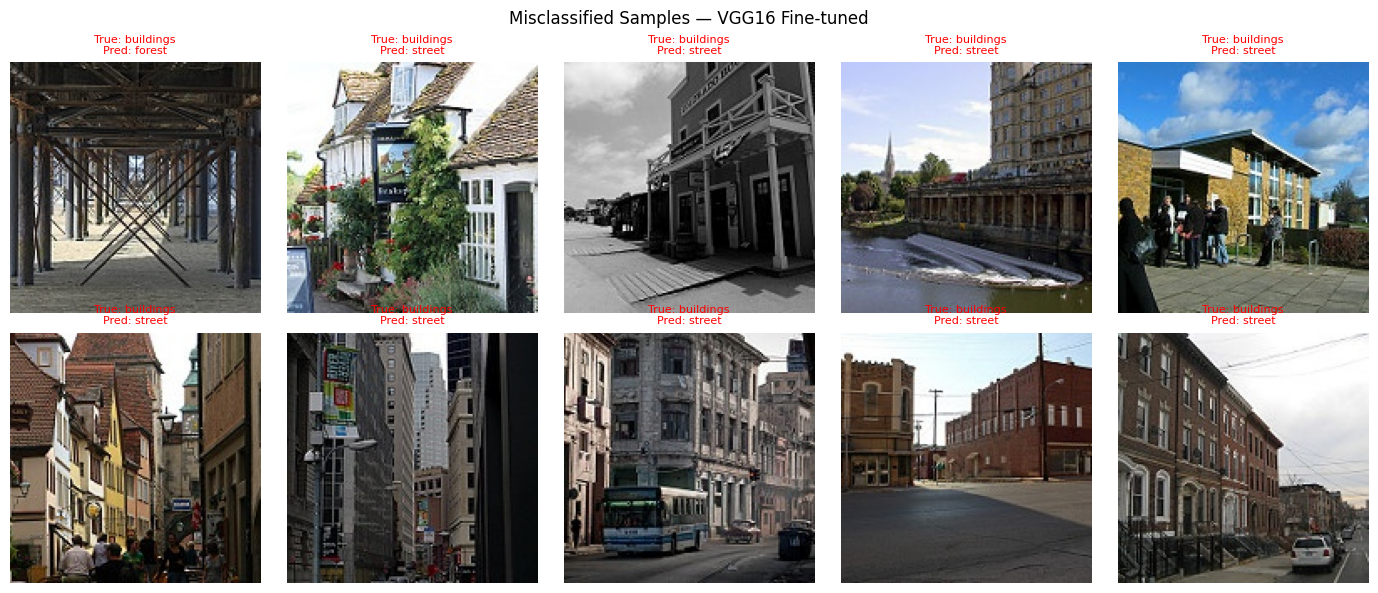

In [28]:
# Use VGG16 fine-tuned predictions
y_pred = np.argmax(vgg_preds, axis=1)   # ← FIX: (3000,6) → (3000,)

wrong_mask = y_pred != test_labels
wrong_imgs = test_images[wrong_mask]
wrong_true = test_labels[wrong_mask]
wrong_pred = y_pred[wrong_mask]

print(f"Total misclassified: {wrong_mask.sum()} / {len(test_labels)} "
      f"({wrong_mask.mean()*100:.1f}%)")

# Top confused pairs
from collections import Counter
pairs = Counter(zip(wrong_true, wrong_pred)).most_common(5)
print("\nTop confused pairs (true → predicted):")
for (t, p), cnt in pairs:
    print(f"  {class_names[t]:10} → {class_names[p]:10}  {cnt} times")

# Plot misclassified samples
n_show = min(10, len(wrong_imgs))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flatten()[:n_show]):
    ax.imshow(wrong_imgs[i].astype('uint8'))
    ax.set_title(f"True: {class_names[wrong_true[i]]}\nPred: {class_names[wrong_pred[i]]}",
                 fontsize=8, color='red')
    ax.axis('off')
plt.suptitle("Misclassified Samples — VGG16 Fine-tuned", fontsize=12)
plt.tight_layout(); plt.show()

In [31]:
# Save in native Keras 3 format (recommended — for reloading with load_model)
vgg_model.save('models/intel_vgg16_finetuned_final.keras')
print("Model saved → models/intel_vgg16_finetuned_final.keras")

# Export as SavedModel for TF Serving / TFLite deployment (Keras 3 way)
vgg_model.export('models/intel_vgg16_savedmodel')
print("SavedModel exported → models/intel_vgg16_savedmodel/")

Model saved → models/intel_vgg16_finetuned_final.keras
INFO:tensorflow:Assets written to: models/intel_vgg16_savedmodel/assets


INFO:tensorflow:Assets written to: models/intel_vgg16_savedmodel/assets


Saved artifact at 'models/intel_vgg16_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_24')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  136848533509456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848536611024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848533507920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848648459408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848648459984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848648459600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848648457104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848648458448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848648456144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136848648455760: TensorSpec(shape=(), dtype=tf.resource, name=None)


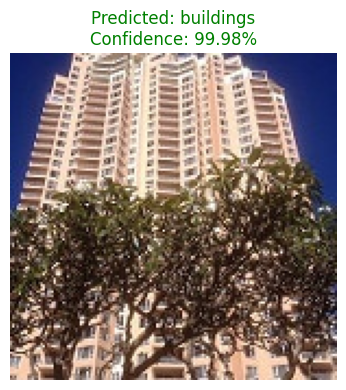


Class Probabilities:
  buildings   █████████████████████████████   99.98% ← predicted
  street                                      0.02%
  glacier                                     0.00%
  sea                                         0.00%
  mountain                                    0.00%
  forest                                      0.00%

True label : buildings
Predicted  : buildings  (99.98%)


In [37]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def predict_image(img_path, model=vgg_model, class_names=class_names,
                  preproc='vgg16'):
    """
    Predict the class of a single image file.
    preproc: 'vgg16' | 'norm'  (use 'norm' for the baseline CNN)
    """
    img = load_img(img_path, target_size=IMG_SIZE)
    arr = img_to_array(img).astype('float32')

    if preproc == 'vgg16':
        arr_inp = vgg_preprocess(arr[np.newaxis])[0]
    else:
        arr_inp = arr / 255.0

    # Use model() directly — faster than model.predict() for single images
    probs = model(arr_inp[np.newaxis], training=False).numpy()[0]
    pred  = np.argmax(probs)

    # Plot
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"Predicted: {class_names[pred]}\nConfidence: {probs[pred]:.2%}",
              fontsize=12, color='green' if probs[pred] > 0.7 else 'orange')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # Probability bar chart
    print("\nClass Probabilities:")
    for name, prob in sorted(zip(class_names, probs), key=lambda x: -x[1]):
        bar   = '█' * int(prob * 30)
        marker = ' ← predicted' if name == class_names[pred] else ''
        print(f"  {name:10}  {bar:<30}  {prob:.2%}{marker}")

    return class_names[pred], float(probs[pred])


# ── Example usage ─────────────────────────────────────────────
# Pick any test image to verify
sample_path_idx = 0
sample_img      = test_images[sample_path_idx].astype('uint8')

# Save temporarily and predict
import cv2
tmp_path = '/tmp/sample_test.jpg'
cv2.imwrite(tmp_path, cv2.cvtColor(sample_img, cv2.COLOR_RGB2BGR))

predicted_class, confidence = predict_image(tmp_path)
print(f"\nTrue label : {class_names[test_labels[sample_path_idx]]}")
print(f"Predicted  : {predicted_class}  ({confidence:.2%})")